In [4]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
#import seaborn as sns
import datetime # Import datetime module for robust date handling

In [6]:
# --- 1. Simulate Data (Replace with your actual data loading) ---
# For demonstration, let's create a synthetic dataset
# In a real scenario, you would load your traffic data (e.g., from a CSV)
df = pd.read_csv('synthetic_4g_network_data.csv')  # Remplace avec ton fichier

In [8]:

np.random.seed(42) # for reproducibility
n_hours = 24 * 30 * 6 # 6 months of hourly data

In [10]:
# Create a time index
dates = pd.date_range(start='2024-01-01', periods=n_hours, freq='H')

# Simulate a base traffic pattern (daily and weekly seasonality)
hour_of_day = np.array(dates.hour)
day_of_week = np.array(dates.dayofweek) # Monday=0, Sunday=6

C:\Users\user\AppData\Local\Temp\ipykernel_15628\2247699560.py:2: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  dates = pd.date_range(start='2024-01-01', periods=n_hours, freq='H')


In [12]:

# Base traffic with daily peaks around evening
base_traffic = 100 + 50 * np.sin(2 * np.pi * hour_of_day / 24)

# Add weekly variations (e.g., lower on weekends)
weekly_factor = np.where(day_of_week >= 5, 0.8, 1.0) # Reduce traffic on weekends

In [14]:
# Add some trend and noise
trend = np.linspace(0, 50, n_hours)
noise = np.random.normal(0, 15, n_hours)
print(type(hour_of_day))

print(type(base_traffic))
print(type(weekly_factor))
print(type(trend))
print(type(noise))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [16]:
# Combine to get simulated traffic
traffic = (base_traffic * weekly_factor + trend + noise).round(2)
traffic[traffic < 0] = 0 # Ensure no negative traffic

df = pd.DataFrame({'timestamp': dates, 'traffic_mbps': traffic})
df.set_index('timestamp', inplace=True)

print("Simulated Data Head:")
print(df.head())
print("\nSimulated Data Info:")
df.info()
print("\n--- Starting LSTM Model Setup ---")

Simulated Data Head:
                     traffic_mbps
timestamp                        
2024-01-01 00:00:00        107.45
2024-01-01 01:00:00        110.88
2024-01-01 02:00:00        134.74
2024-01-01 03:00:00        158.24
2024-01-01 04:00:00        139.84

Simulated Data Info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4320 entries, 2024-01-01 00:00:00 to 2024-06-28 23:00:00
Data columns (total 1 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   traffic_mbps  4320 non-null   float64
dtypes: float64(1)
memory usage: 67.5 KB

--- Starting LSTM Model Setup ---


In [18]:
# --- 2. Data Preprocessing and Scaling ---
# LSTMs are sensitive to data scale, so normalization is crucial.

# Use only the 'traffic_mbps' column for simple univariate LSTM for now
# For multivariate LSTM, you'd include other features here as well.
data = df['traffic_mbps'].values.reshape(-1, 1) # Reshape for MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

In [20]:
# --- 3. Create Sequences for LSTM ---
# This is where we transform our time series into sequences (look-back windows).

def create_sequences(data, look_back):
    X, y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i:(i + look_back), 0]) # Input sequence (look_back observations)
        y.append(data[i + look_back, 0])     # Target (the next observation)
    return np.array(X), np.array(y)

look_back = 24 # Number of previous hours to consider for prediction (e.g., 24 hours)
X, y = create_sequences(scaled_data, look_back)

In [22]:
# Reshape input to be [samples, timesteps, features] for LSTM
# Here, features is 1 because we are only using 'traffic_mbps' as input feature
X = np.reshape(X, (X.shape[0], X.shape[1], 1))

print(f"\nShape of X (sequences): {X.shape}") # (samples, timesteps, features)
print(f"Shape of y (targets): {y.shape}")     # (samples,)


Shape of X (sequences): (4296, 24, 1)
Shape of y (targets): (4296,)


In [24]:
# --- 4. Splitting Data (Time Series Split) ---
# Maintain chronological order for time series.

# Let's use the last 10% of the data for testing
train_size = int(len(X) * 0.9)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"Training data shape (X_train): {X_train.shape}")
print(f"Testing data shape (X_test): {X_test.shape}")
print(f"Training target shape (y_train): {y_train.shape}")
print(f"Testing target shape (y_test): {y_test.shape}")

Training data shape (X_train): (3866, 24, 1)
Testing data shape (X_test): (430, 24, 1)
Training target shape (y_train): (3866,)
Testing target shape (y_test): (430,)


In [26]:
# --- 5. Build the LSTM Model ---
model = Sequential()

# First LSTM layer
# return_sequences=True if you want to stack more LSTM layers
model.add(LSTM(units=50, return_sequences=True, input_shape=(look_back, 1)))
model.add(Dropout(0.2)) # Dropout for regularization to prevent overfitting

# Second LSTM layer (optional, remove return_sequences=True from previous if only one LSTM)
model.add(LSTM(units=50, return_sequences=False)) # return_sequences=False for the last LSTM layer before Dense
model.add(Dropout(0.2))

# Output layer (Dense layer for single value prediction)
model.add(Dense(units=1))

# Compile the model
# optimizer: 'adam' is a good general-purpose optimizer
# loss: 'mean_squared_error' is suitable for regression
model.compile(optimizer='adam', loss='mean_squared_error')

print("\nLSTM Model Summary:")
model.summary()

C:\Users\user\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



LSTM Model Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)


Training LSTM model...
Epoch 1/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 14s 38ms/step - loss: 0.0733 - val_loss: 0.0135
Epoch 2/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0115 - val_loss: 0.0071
Epoch 3/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.0092 - val_loss: 0.0081
Epoch 4/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.0088 - val_loss: 0.0064
Epoch 5/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 0.0090 - val_loss: 0.0070
Epoch 6/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.0087 - val_loss: 0.0069
Epoch 7/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0081 - val_loss: 0.0062
Epoch 8/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 0.0092 - val_loss: 0.0066
Epoch 9/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.0079 - val_loss: 0.0089
Epoch 10/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.0092 - val_loss: 0.0067
Epoch 11/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.0083 - val_loss: 0.0076
Epoch

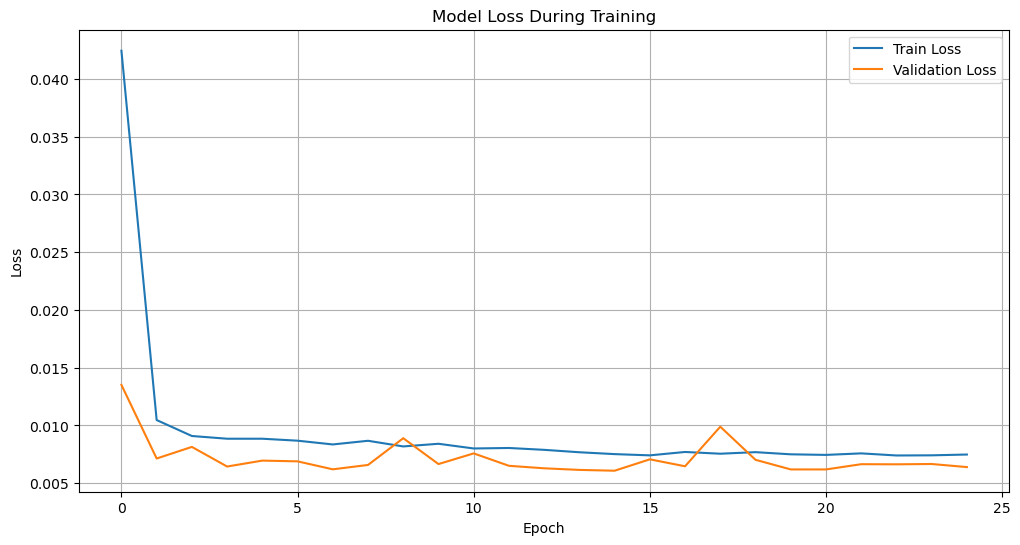

In [28]:
# --- 6. Train the LSTM Model ---

# EarlyStopping to prevent overfitting and stop training when validation loss stops improving
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

print("\nTraining LSTM model...")
history = model.fit(X_train, y_train,
                    epochs=100, # Number of training iterations
                    batch_size=32, # Number of samples per gradient update
                    validation_split=0.1, # Use a part of training data for validation
                    callbacks=[early_stopping],
                    verbose=1)
print("Model training complete.")

# Plot training & validation loss values
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss During Training')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [29]:
# --- 7. Make Predictions ---

# Get predictions on the test set
scaled_predictions = model.predict(X_test)

# Invert predictions and actual values back to original scale
predictions = scaler.inverse_transform(scaled_predictions)
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1)) # Reshape for inverse_transform

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step


In [30]:
# --- 8. Evaluate the Model ---

mse = mean_squared_error(y_test_actual, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_actual, predictions)
r2 = r2_score(y_test_actual, predictions)
mape = np.mean(np.abs((y_test_actual - predictions) / y_test_actual)) * 100

print(f"\nModel Evaluation on Test Set:")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R-squared (R2): {r2:.2f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}")



Model Evaluation on Test Set:
Mean Squared Error (MSE): 295.53
Root Mean Squared Error (RMSE): 17.19
Mean Absolute Error (MAE): 13.73
R-squared (R2): 0.80
Mean Absolute Percentage Error (MAPE): 10.82


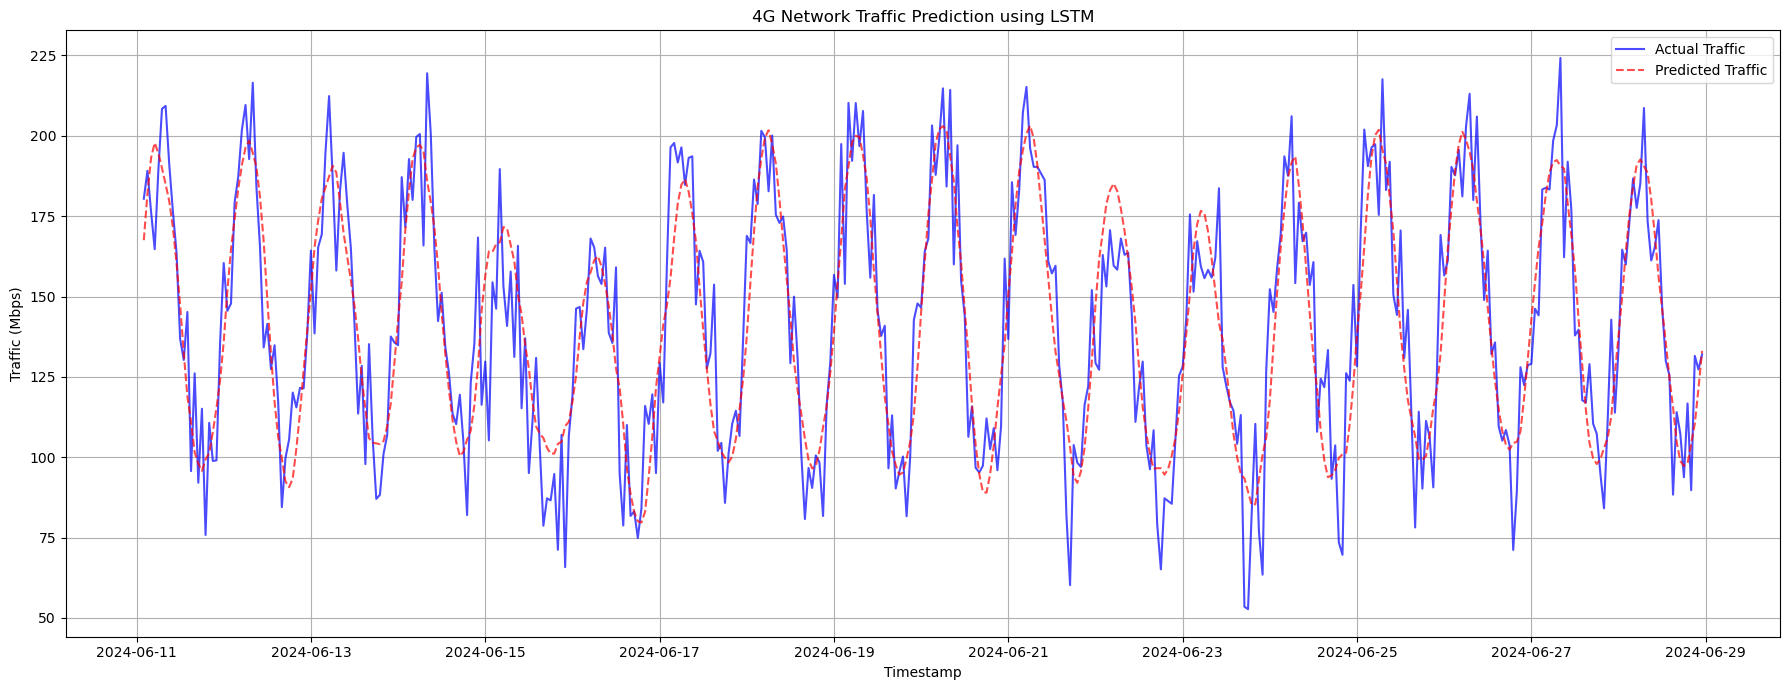

In [31]:
# --- 9. Visualize Results ---

# Create a proper time index for the predictions
# The test set indices start after the training set and the look_back period
# This needs careful alignment as create_sequences shifts the data.

# Get the original index for the test set
# The 'y_test' corresponds to data points starting from 'train_size + look_back' in the original 'scaled_data'
# So, the corresponding original timestamps would be from 'df.index[look_back + train_size_original:]'
# Note: 'train_size' here refers to the split point *after* sequencing, not in the original df.
# Let's reconstruct the index for plotting accurately.

# The original index of the data used for X, y creation
original_indexed_data = df['traffic_mbps'].iloc[look_back:].index

# The index for the test set predictions
test_index_start = len(original_indexed_data) - len(y_test_actual)
test_timestamps = original_indexed_data[test_index_start:]

plt.figure(figsize=(18, 7))
plt.plot(test_timestamps, y_test_actual, label='Actual Traffic', color='blue', alpha=0.7)
plt.plot(test_timestamps, predictions, label='Predicted Traffic', color='red', linestyle='--', alpha=0.7)
plt.title('4G Network Traffic Prediction using LSTM')
plt.xlabel('Timestamp')
plt.ylabel('Traffic (Mbps)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

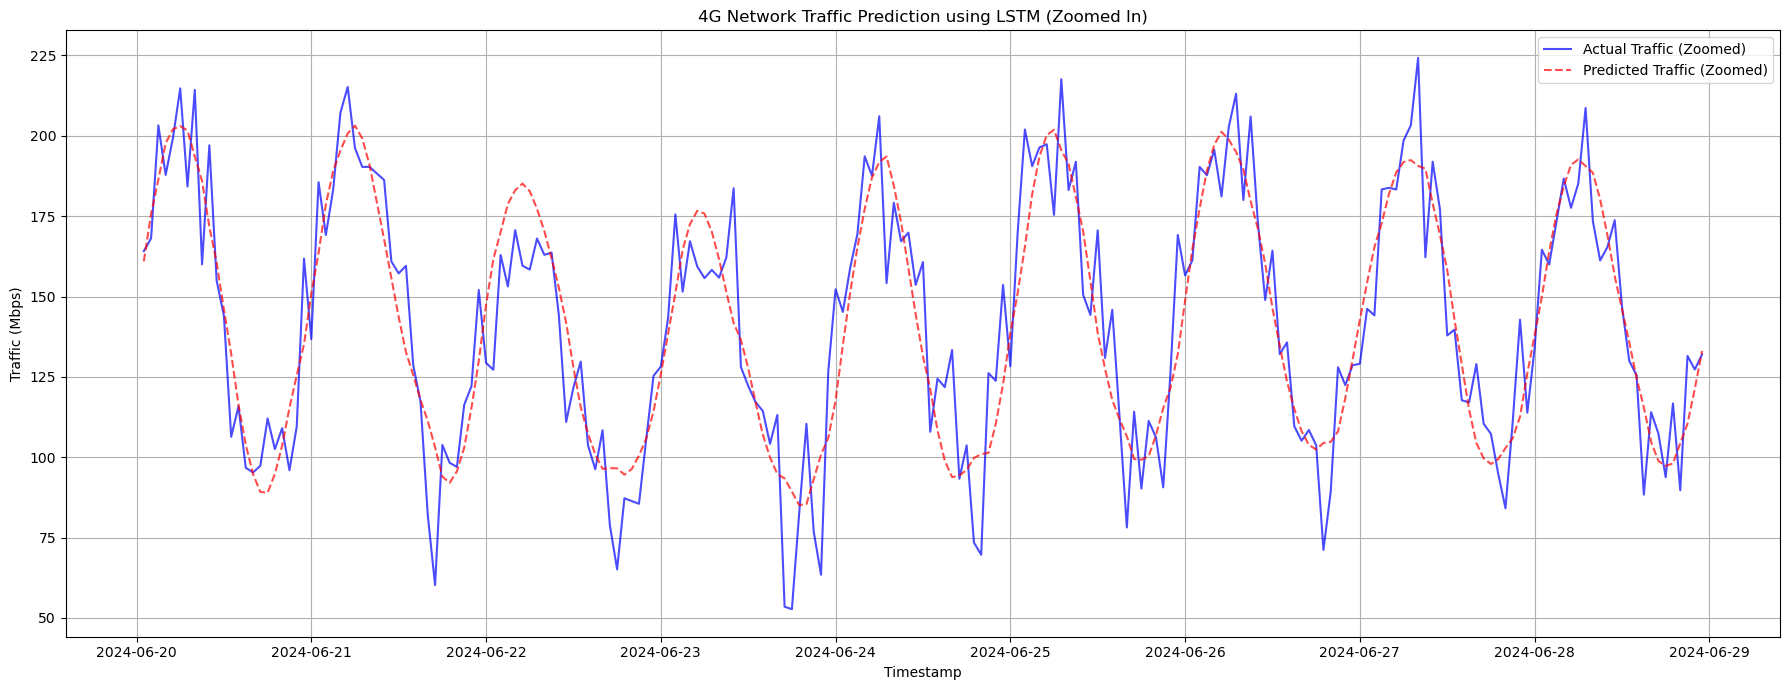

In [32]:
# Optional: Plot a zoomed-in section
plt.figure(figsize=(18, 7))
zoom_start = len(test_timestamps) // 2 # Start from middle of test set for zoom
plt.plot(test_timestamps[zoom_start:], y_test_actual[zoom_start:], label='Actual Traffic (Zoomed)', color='blue', alpha=0.7)
plt.plot(test_timestamps[zoom_start:], predictions[zoom_start:], label='Predicted Traffic (Zoomed)', color='red', linestyle='--', alpha=0.7)
plt.title('4G Network Traffic Prediction using LSTM (Zoomed In)')
plt.xlabel('Timestamp')
plt.ylabel('Traffic (Mbps)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
